# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


In [2]:
GREY = '#BBBBBB'; ACCENT = '#E69F00'; BLUE = '#0072B2'
okabe = {'Africa':'#E69F00','Asia':'#0072B2','Europe':'#009E73',
         'North America':'#CC79A7','Oceania':'#56B4E9','South America':'#D55E00'}

In [13]:
import textwrap

def tidy(fig, width=75):
    """Wrap long titles onto several lines and leave room for them."""
    title = fig.layout.title.text or ''
    if '<br>' not in title:                      # skip titles already split by hand
        fig.update_layout(title_text='<br>'.join(textwrap.wrap(title, width)))
    fig.update_layout(title_font_size=18, margin=dict(t=110))
    return fig

---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*  In this, we only need the change between years for each continent, not the comparison between continents; a proper line graph can explain the population growth through out the time frame (1970-2022). Here each coloumn is indexed to its 1970's size of population . As the questions asks about the particular continent highlighted orange for africa grabs the eye at the needed point and the rest are in grey color.

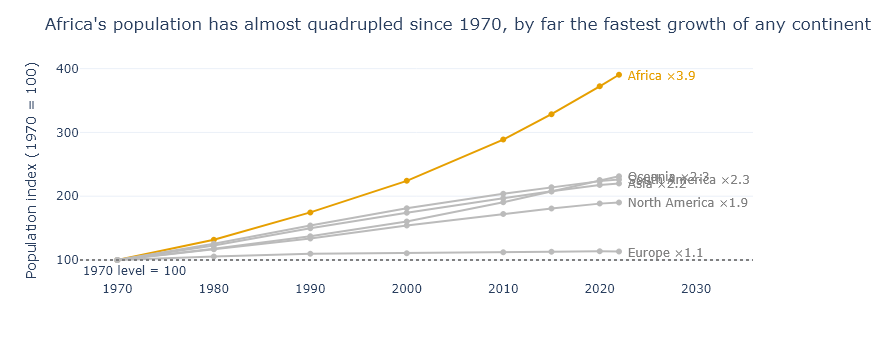

In [14]:
# Q1
# YOUR CODE HERE

cont = df_long.groupby(['Continent','Year'], as_index=False)['Population'].sum().sort_values(['Continent','Year'])
base = cont[cont['Year']==1970].set_index('Continent')['Population']
cont['Index'] = cont['Population'] / cont['Continent'].map(base) * 100

colors = {c: GREY for c in cont['Continent'].unique()}; colors['Africa'] = ACCENT
fig = px.line(cont, x='Year', y='Index', color='Continent', color_discrete_map=colors,
              markers=True, template='plotly_white')

for _, r in cont[cont['Year']==2022].iterrows():
    fig.add_annotation(x=2022, y=r['Index'], text=f"{r['Continent']} ×{r['Index']/100:.1f}",
                       showarrow=False, xanchor='left', xshift=6,
                       font=dict(color=ACCENT if r['Continent']=='Africa' else 'grey'))
fig.add_hline(y=100, line_dash='dot', line_color='grey',
              annotation_text='1970 level = 100', annotation_position='bottom left')

fig.update_layout(title="Africa's population has almost quadrupled since 1970, by far the fastest growth of any continent",
                  showlegend=False, margin=dict(r=140))
fig.update_xaxes(title=None, showgrid=False)
fig.update_yaxes(title='Population index (1970 = 100)')
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*  Ranking 15 countries with long names suits a sorted horizontal bar. Colour answers the “how many in Africa” part directly: Africa in orange, the rest grey. And the base line starts from zero justifies the bar length,


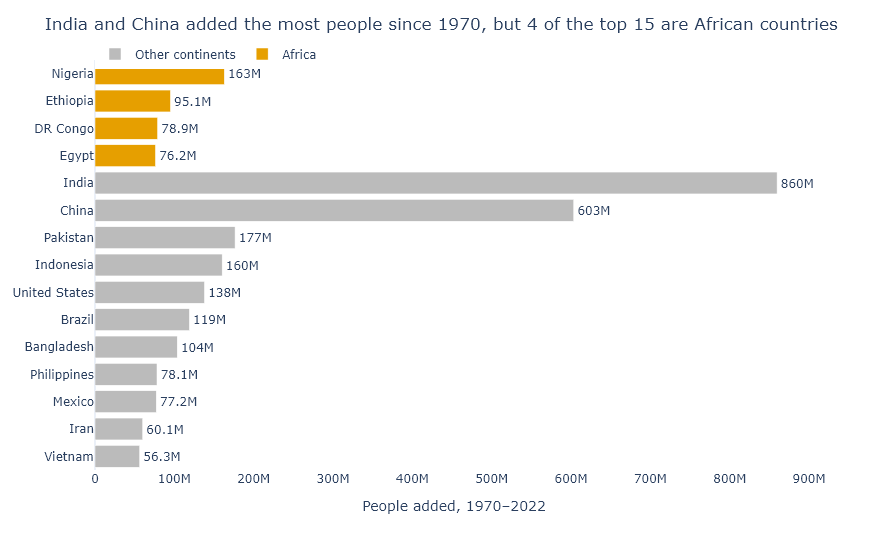

In [15]:
# Q2
# YOUR CODE HERE

d = df.assign(Added=df['2022 Population'] - df['1970 Population'])
top15 = d.nlargest(15, 'Added').sort_values('Added')
top15['Group'] = np.where(top15['Continent']=='Africa', 'Africa', 'Other continents')
n_af = (top15['Continent']=='Africa').sum()

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group',
             color_discrete_map={'Africa': ACCENT, 'Other continents': GREY}, template='plotly_white')
fig.update_traces(texttemplate='%{x:.3s}', textposition='outside')
fig.update_layout(title=f'India and China added the most people since 1970, but {n_af} of the top 15 are African countries',
                  legend=dict(title=None, orientation='h', y=1.05, x=0), height=550)
fig.update_xaxes(title='People added, 1970–2022', showgrid=False)
fig.update_yaxes(title=None)
fig.show()

---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* Now it's a relationship between two numeric variables, and there are a large number of countries, so a scatter plot fits perfectly. Otherwise, some countries like China and India would squash everything in the space. Both axes use a log scale because area and population span many orders of magnitude, and annotations name the countries that break the pattern.

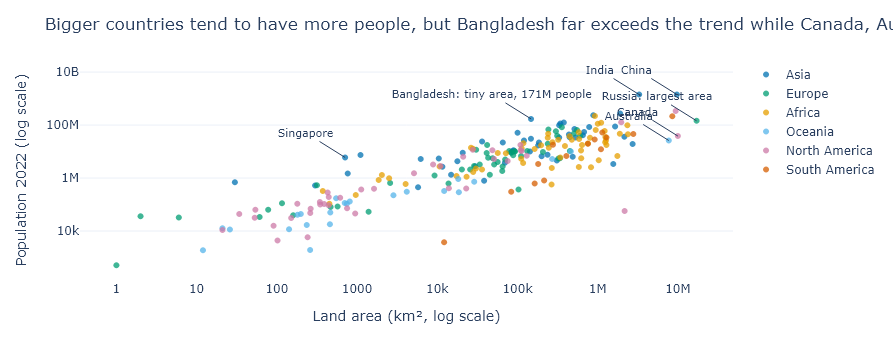

In [16]:
# Q3
# YOUR CODE HERE

fig = px.scatter(df, x='Area', y='2022 Population', color='Continent', color_discrete_map=okabe,
                 log_x=True, log_y=True, hover_name='Country', opacity=0.75, template='plotly_white')

labels = {'Bangladesh':'Bangladesh: tiny area, 171M people', 'Russia':'Russia: largest area',
          'Canada':'Canada', 'Australia':'Australia', 'Singapore':'Singapore', 'India':'India', 'China':'China'}
for c, txt in labels.items():
    r = df[df['Country']==c].iloc[0]
    fig.add_annotation(x=np.log10(r['Area']), y=np.log10(r['2022 Population']),   # log axes need log10 positions
                       text=txt, showarrow=True, arrowhead=0, ax=-40, ay=-25, font=dict(size=11))

fig.update_layout(title='Bigger countries tend to have more people, but Bangladesh far exceeds the trend while Canada, Australia and Russia fall well below it',
                  legend=dict(title=None))
fig.update_xaxes(title='Land area (km², log scale)', showgrid=False)
fig.update_yaxes(title='Population 2022 (log scale)')
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* “Show the spread, not just the average” calls for a box plot :median, IQR and outliers per continent. Horizontal, sorted by median, with a log scale because Macau (23,000/km²) would squash every other box. A world-median reference line gives context, and a single colour is used because continent is already on the axis.

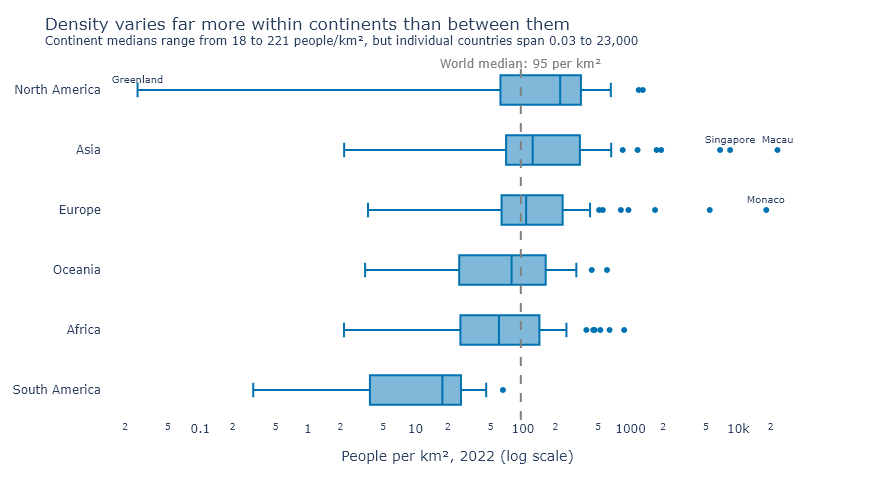

In [17]:
order = df.groupby('Continent')['Density'].median().sort_values().index.tolist()
world_med = df['Density'].median()

fig = px.box(df, x='Density', y='Continent', orientation='h', points='outliers', log_x=True,
             category_orders={'Continent': order[::-1]}, hover_name='Country',
             color_discrete_sequence=[BLUE], template='plotly_white')

# Reference line WITHOUT built-in label (avoids the log-axis bug)
fig.add_vline(x=world_med, line_dash='dash', line_color='grey')
# Label added separately: on a log axis, x must be given as log10(value)
fig.add_annotation(x=np.log10(world_med), y=1.02, yref='paper', showarrow=False,
                   text=f'World median: {world_med:.0f} per km²', font=dict(color='grey'))

# Label the most extreme outliers so the story is visible
for c in ['Macau', 'Monaco', 'Singapore', 'Greenland']:
    r = df[df['Country'] == c].iloc[0]
    fig.add_annotation(x=np.log10(r['Density']), y=r['Continent'], text=c,
                       showarrow=False, yshift=12, font=dict(size=10))

fig.update_layout(
    title='Density varies far more within continents than between them<br>'
          '<sup>Continent medians range from 18 to 221 people/km², but individual countries span 0.03 to 23,000</sup>',
    height=500)
fig.update_xaxes(title='People per km², 2022 (log scale)', showgrid=False)
fig.update_yaxes(title=None)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* “Where in the world” means geography, so a choropleth. Growth vs shrinkage needs a diverging scale centred at 0%. Purple–orange (PuOr) is CVD-safe. The scale is capped at +100% so Qatar (+317%) doesn’t wash everything out, and the cap is disclosed.

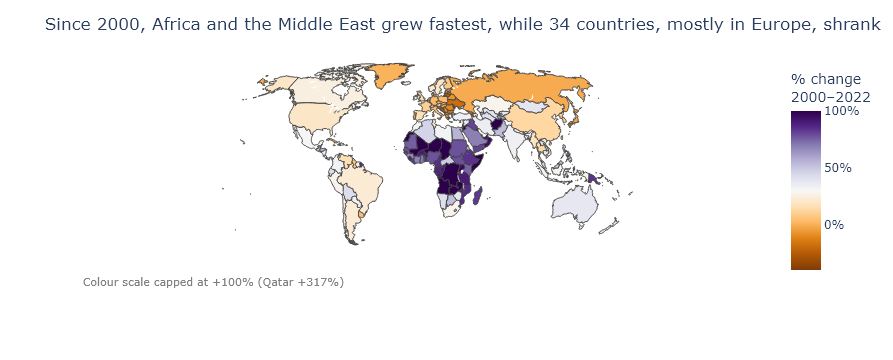

In [18]:
# Q5
# YOUR CODE HERE

d = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)
n_shrunk = (d['Change'] < 0).sum()

fig = px.choropleth(d, locations='CCA3', locationmode='ISO-3', color='Change', hover_name='Country',
                    color_continuous_scale='PuOr', color_continuous_midpoint=0, range_color=[-40, 100],
                    template='plotly_white')
fig.update_geos(showframe=False, showcoastlines=False, projection_type='natural earth')
fig.update_layout(title=f'Since 2000, Africa and the Middle East grew fastest, while {n_shrunk} countries, mostly in Europe, shrank',
                  coloraxis_colorbar=dict(title='% change<br>2000–2022', ticksuffix='%'))
fig.add_annotation(text='Colour scale capped at +100% (Qatar +317%)', x=0, y=-0.05,
                   xref='paper', yref='paper', showarrow=False, font=dict(size=11, color='grey'))
fig.show()



---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* Here we have parts as continents and pieces of parts as countires then a treemap fits perfeclty(two levels), Area = population, colour = continent, and labels show each block’s share of the world.

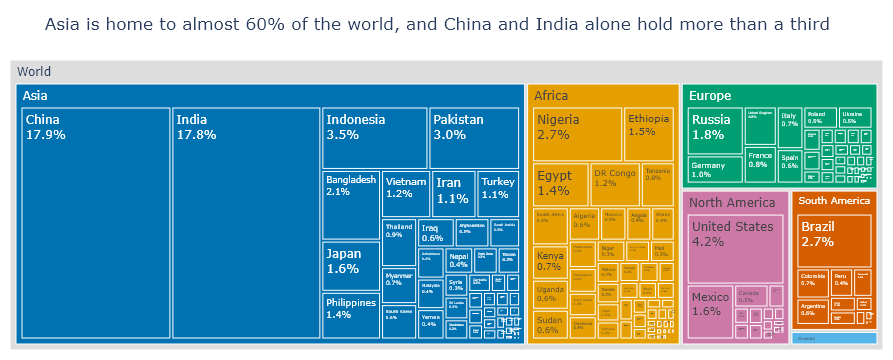

In [19]:
# Q6
# YOUR CODE HERE

fig = px.treemap(df, path=[px.Constant('World'), 'Continent', 'Country'], values='2022 Population',
                 color='Continent', color_discrete_map={**okabe, '(?)': '#DDDDDD'}, template='plotly_white')
fig.update_traces(texttemplate='%{label}<br>%{percentRoot:.1%}', root_color='lightgrey')
fig.update_layout(title='Asia is home to almost 60% of the world, and China and India alone hold more than a third',
                  margin=dict(t=60, l=10, r=10, b=10))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* Shares of a whole compared across years suit a 100% stacked bar. Africa (rising) is the orange accent and Europe (falling) is blue; Asia and the rest are grey context. Africa sits at the bottom so its change is easy to read against the baseline, and percentage labels sit inside the bars

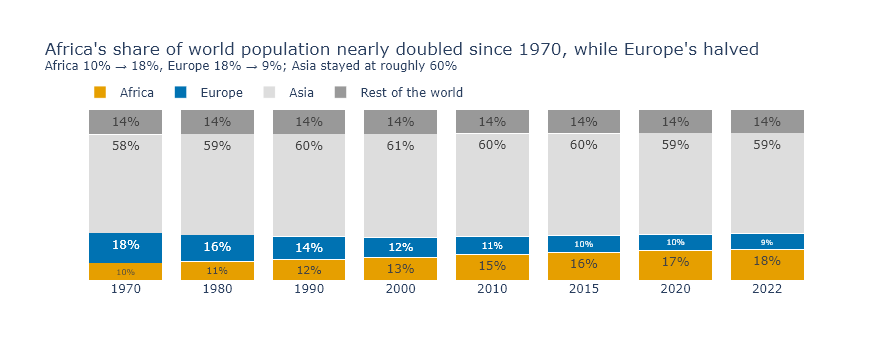

In [20]:
# Q7
# YOUR CODE HERE

s = df_long.copy()
s['Group'] = s['Continent'].where(s['Continent'].isin(['Africa','Asia','Europe']), 'Rest of the world')
share = s.groupby(['Year','Group'], as_index=False)['Population'].sum()
share['Share'] = share['Population'] / share.groupby('Year')['Population'].transform('sum') * 100

fig = px.bar(share, x='Year', y='Share', color='Group', text='Share',
             category_orders={'Group': ['Africa','Europe','Asia','Rest of the world']},
             color_discrete_map={'Africa': ACCENT, 'Europe': BLUE, 'Asia': '#DDDDDD', 'Rest of the world': '#999999'},
             template='plotly_white')
fig.update_traces(texttemplate='%{text:.0f}%', textposition='inside')
fig.update_layout(
    barmode='stack',
    title="Africa's share of world population nearly doubled since 1970, while Europe's halved"
          "<br><sup>Africa 10% → 18%, Europe 18% → 9%; Asia stayed at roughly 60%</sup>",
    legend=dict(title=None, orientation='h', y=1.02, x=0, yanchor='bottom'),
    margin=dict(t=110)
)
fig.update_xaxes(title=None, type='category')
fig.update_yaxes(visible=False, range=[0, 100])   # labels already show the %
fig.show()